# Spark 4 (Spark Connect, ANSI Mode, VARIANT)

Spark 4.0 (2025) is the first major release since Spark 3.0 (2020). It changes how clients talk to Spark (**Spark
Connect**), how Spark treats bad data (**ANSI mode** is on by default), and how it stores semi-structured data
(the **VARIANT** type). It also lets you write data sources and table functions in plain Python. This lesson
checks each feature in the installed version, pyspark 4.2.0, on taxi data.

**After this lesson you can:**

1. Start a Spark Connect server, connect a thin client over gRPC, and say what the client cannot do.
2. Predict how ANSI mode handles invalid casts, overflow and division by zero, and use the `try_*` functions.
3. Store JSON events as VARIANT and query them with `variant_get`, and compare this with JSON strings.
4. Write a Python data source, a Python table function (UDTF) and a query in SQL pipe syntax.

**Data:** NYC yellow taxi trips, January 2024, and the taxi zone lookup table.
**Services:** none (Spark runs locally in the notebook; the Spark Connect server runs inside the same JVM).

In [1]:
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.errors import PySparkException
from pyspark.logger import PySparkLogger
from pyspark.sql import SparkSession, functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
OUT = Path(tempfile.gettempdir()) / "fzth-m13" / "l11"
shutil.rmtree(OUT, ignore_errors=True)
OUT.mkdir(parents=True)

spark = (SparkSession.builder.master("local[4]").appName("m13-l11")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.plugins", "org.apache.spark.sql.connect.SparkConnectPlugin")   # also serve Spark Connect
         .config("spark.connect.grpc.binding.port", "15002")
         .config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("FATAL")       # section 3 provokes errors on purpose; hide the JVM error logs
for name in ["SQLQueryContextLogger", "DataFrameQueryContextLogger"]:      # we print the errors ourselves
    PySparkLogger.getLogger(name).setLevel("CRITICAL")
JAN, ZONES = str(datasets.taxi("2024-01")), str(datasets.fetch("taxi_zone_lookup.csv"))
spark.read.parquet(JAN).createOrReplaceTempView("trips")
spark.read.option("header", True).option("inferSchema", True).csv(ZONES).createOrReplaceTempView("zones")
print("Spark", spark.version, "| trips:", f'{spark.table("trips").count():,}')

def error_name(e: Exception) -> str:
    """The error condition of a Spark exception (Spark 4 names every error)."""
    return e.getCondition() if isinstance(e, PySparkException) and e.getCondition() else type(e).__name__

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/24 21:15:53 WARN Utils: Your hostname, Muhammet, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/24 21:15:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/24 21:15:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | trips: 2,964,624


## 1. What Changed in Spark 4

The cell runs one small statement per feature in this Spark version and reports whether it works. Spark Connect has
its own section below.

In [2]:
checks = {
    "ANSI SQL mode on by default": ("SELECT 1", lambda: spark.conf.get("spark.sql.ansi.enabled")),
    "VARIANT type (parse_json)": ("SELECT variant_get(parse_json('{\"a\": 42}'), '$.a', 'int')", None),
    "SQL pipe syntax (|>)": ("FROM zones |> WHERE Borough = 'Queens' |> AGGREGATE COUNT(*) AS n", None),
    "String collations": ("SELECT 'Taxi' = 'TAXI' COLLATE UTF8_LCASE", None),
    "SQL session variables": ("DECLARE OR REPLACE VARIABLE min_fare DOUBLE DEFAULT 2.5", None),
    "try_* functions": ("SELECT try_divide(1, 0), try_cast('12a' AS INT)", None),
}
rows = []
for feature, (stmt, extra) in checks.items():
    try:
        res = spark.sql(stmt).collect()
        value = extra() if extra else (res[0][0] if res else "ok")
        rows.append({"feature": feature, "works": True, "result": value})
    except Exception as e:
        rows.append({"feature": feature, "works": False, "result": error_name(e)})
for feature, mod in [("Python data source API", "pyspark.sql.datasource"), ("Python UDTFs", "pyspark.sql.udtf")]:
    try:
        __import__(mod); rows.append({"feature": feature, "works": True, "result": f"module {mod}"})
    except ImportError as e:
        rows.append({"feature": feature, "works": False, "result": str(e)})
print(pd.DataFrame(rows).to_string(index=False))

                    feature  works                        result
ANSI SQL mode on by default   True                          true
  VARIANT type (parse_json)   True                            42
       SQL pipe syntax (|>)   True                            69
          String collations   True                          True
      SQL session variables   True                            ok
            try_* functions   True                          None
     Python data source API   True module pyspark.sql.datasource
               Python UDTFs   True       module pyspark.sql.udtf


| Feature | What it gives you |
| :--- | :--- |
| Spark Connect | a thin client that sends query plans over gRPC; clients in Python, Scala, Go, Rust, ... |
| ANSI mode by default | invalid casts, overflow and division by zero raise an error instead of a silent NULL or a wrong number |
| VARIANT | semi-structured data (JSON) in a binary format that Spark can query fast, without a fixed schema |
| Python data source API | custom readers and writers in Python, used with `spark.read.format(...)` |
| Python UDTFs | table functions in Python: one input row can produce many output rows |
| SQL pipe syntax | queries written as a chain of steps (`FROM t |> WHERE ... |> AGGREGATE ...`) |
| Collations | case- and accent-insensitive string comparison (`COLLATE UTF8_LCASE`) |

## 2. Spark Connect

In classic PySpark, the Python process starts a JVM and controls it through Py4J: the client and the driver are
one program. With **Spark Connect**, the driver is a server. The client builds an **unresolved logical plan**,
sends it as a Protocol Buffers message over gRPC (port 15002), and receives the result as Arrow batches. The client
needs no JVM, a crash in the client does not kill the driver, and the server can be upgraded without the clients.

Here the server is a plugin of the notebook's Spark session (`spark.plugins` in the setup cell). A production server
starts with `sbin/start-connect-server.sh`; `SparkSession.builder.remote("local[*]")` starts a local one for you.

In [3]:
from pyspark.sql.connect.session import SparkSession as ConnectSession
from pyspark.sql.connect import functions as CF       # Column functions of the Connect client

cspark = ConnectSession.builder.remote("sc://localhost:15002").getOrCreate()
print("client class:", type(cspark).__module__ + "." + type(cspark).__name__, "| server Spark:", cspark.version)

ctrips = cspark.read.parquet(JAN)
czones = cspark.read.option("header", True).option("inferSchema", True).csv(ZONES)
cquery = (ctrips.join(czones, ctrips.PULocationID == czones.LocationID)
          .groupBy("Borough").agg(CF.count("*").alias("trips"), CF.round(CF.sum("total_amount"), 2).alias("revenue"))
          .orderBy(CF.desc("revenue")))
plan = cquery._plan.to_proto(cspark.client)           # internal API: the message the client sends
print(f"plan message: {plan.ByteSize()} bytes of protobuf (the data stays on the server)")
print(str(plan.root)[:300], "...")

remote = cquery.toPandas()                             # the result comes back as Arrow batches
print(remote.to_string(index=False))
classic = spark.sql("""SELECT Borough, COUNT(*) AS trips, ROUND(SUM(total_amount), 2) AS revenue
                       FROM trips JOIN zones ON PULocationID = LocationID GROUP BY Borough ORDER BY revenue DESC""").toPandas()
print("same result as the classic session:", remote.equals(classic))

client class: pyspark.sql.connect.session.SparkSession | server Spark: 4.2.0
plan message: 591 bytes of protobuf (the data stays on the server)
common {
  plan_id: 4
}
sort {
  input {
    common {
      plan_id: 3
    }
    aggregate {
      input {
        common {
          plan_id: 2
        }
        join {
          left {
            common {
              plan_id: 0
            }
            read {
              data_source {
       ...


      Borough   trips     revenue
    Manhattan 2646948 59247529.17
       Queens  273128 18639792.67
     Brooklyn   25258   828808.42
      Unknown   10360   304152.35
        Bronx    6905   246496.38
          N/A    1658   154900.88
          EWR     295    30738.03
Staten Island      72     3966.38


same result as the classic session: True


The Connect client has no JVM, so everything that needs direct JVM access is missing: the RDD API, `SparkContext`,
`sparkContext.broadcast` and accumulators. The cell tries them.

In [4]:
for name, attempt in [("df.rdd", lambda: ctrips.rdd), ("spark.sparkContext", lambda: cspark.sparkContext),
                      ("df.collect() (DataFrame API)", lambda: len(ctrips.limit(3).collect()))]:
    try:
        print(f"{name:<30} works -> {attempt()}")
    except Exception as e:
        print(f"{name:<30} not supported: {error_name(e)}")
cspark.stop()

df.rdd                         not supported: NOT_IMPLEMENTED
spark.sparkContext             not supported: JVM_ATTRIBUTE_NOT_SUPPORTED


df.collect() (DataFrame API)   works -> 3


*Insight: The client sent a plan of a few hundred bytes and received an 8-row result; the 3 million trips never left
the server. The Connect result is identical to the classic one. Code that uses RDDs or `SparkContext` must be
rewritten with DataFrames before it can run on Spark Connect (for example on Databricks serverless compute).*

## 3. ANSI Mode: Fail on Bad Data

Without ANSI mode, Spark hides bad data: an invalid cast gives NULL, an integer overflow wraps around to a negative
number, and division by zero gives NULL. With ANSI mode (the default in Spark 4), the same expressions stop the
query with a named error. The `try_*` functions give the old NULL result on purpose, for one expression only.

In [5]:
bad = {
    "CAST('12a' AS INT)": "invalid cast",
    "CAST(2147483647 AS INT) + 1": "integer overflow",
    "CAST(fare AS DOUBLE) / 0": "divide by zero",
    "try_cast('12a' AS INT)": "try_cast",
    "try_add(CAST(2147483647 AS INT), 1)": "try_add",
    "try_divide(CAST(fare AS DOUBLE), 0)": "try_divide",
}
spark.createDataFrame([("12.5",)], "fare string").createOrReplaceTempView("one")
rows = []
for expr, what in bad.items():
    row = {"input": what, "expression": expr}
    for ansi in ["false", "true"]:
        spark.conf.set("spark.sql.ansi.enabled", ansi)
        try:
            v = spark.sql(f"SELECT {expr} AS v FROM one").collect()[0].v
            row[f"ANSI {ansi}"] = "NULL" if v is None else str(v)
        except Exception as e:
            row[f"ANSI {ansi}"] = "ERROR " + error_name(e)
    rows.append(row)
spark.conf.set("spark.sql.ansi.enabled", "true")
print(pd.DataFrame(rows).to_string(index=False))

           input                          expression  ANSI false                 ANSI true
    invalid cast                  CAST('12a' AS INT)        NULL  ERROR CAST_INVALID_INPUT
integer overflow         CAST(2147483647 AS INT) + 1 -2147483648 ERROR ARITHMETIC_OVERFLOW
  divide by zero            CAST(fare AS DOUBLE) / 0        NULL      ERROR DIVIDE_BY_ZERO
        try_cast              try_cast('12a' AS INT)        NULL                      NULL
         try_add try_add(CAST(2147483647 AS INT), 1)        NULL                      NULL
      try_divide try_divide(CAST(fare AS DOUBLE), 0)        NULL                      NULL


On real data: some taxi trips have `trip_distance = 0`. A "fare per mile" metric divides by it.

In [6]:
zero = spark.sql("SELECT COUNT(*) FROM trips WHERE trip_distance = 0").collect()[0][0]
print(f"trips with trip_distance = 0: {zero:,}")
for ansi in ["false", "true"]:
    spark.conf.set("spark.sql.ansi.enabled", ansi)
    try:
        r = spark.sql("SELECT COUNT(fare_amount / trip_distance) AS n, ROUND(AVG(fare_amount / trip_distance), 2) AS avg FROM trips").collect()[0]
        print(f"ANSI {ansi}: rows with a value {r.n:,}, average fare per mile {r.avg}")
    except Exception as e:
        print(f"ANSI {ansi}: ERROR {error_name(e)}")
r = spark.sql("""SELECT COUNT(try_divide(fare_amount, trip_distance)) AS n,
                  ROUND(AVG(try_divide(fare_amount, trip_distance)), 2) AS avg FROM trips""").collect()[0]
print(f"ANSI true + try_divide: rows with a value {r.n:,}, average fare per mile {r.avg}")

trips with trip_distance = 0: 60,371


ANSI false: rows with a value 2,904,253, average fare per mile 10.52
ANSI true: ERROR DIVIDE_BY_ZERO


ANSI true + try_divide: rows with a value 2,904,253, average fare per mile 10.52


*Insight: Without ANSI mode, the 60,371 trips with zero distance silently drop out of the average: it uses 2,904,253
of 2,964,624 trips, and nobody is told. The overflow is worse: 2147483647 + 1 gives -2147483648, a wrong number
instead of NULL. With ANSI mode the query stops with `DIVIDE_BY_ZERO`. `try_divide` gives the same 10.52 as before,
but now the code says on purpose that a zero distance means "no value".*

## 4. VARIANT: Semi-Structured Events

Event data often has fields that only some events have. The cell turns January trips into JSON events: a card
payment has a `tip`, an airport trip has an `airport_fee`, a trip with tolls has `tolls`. Fields with no value are
left out, so the events have different shapes. The events are stored twice: as a JSON **string** and as **VARIANT**
(`parse_json`). VARIANT stores the parsed values in a binary format with a field dictionary, so a query reads a
field without parsing text.

In [7]:
events = (spark.table("trips").where("tpep_pickup_datetime < '2024-01-06'")
          .select(F.to_json(F.struct(
              F.lit("trip_completed").alias("event"),
              F.col("tpep_pickup_datetime").cast("string").alias("ts"),
              F.col("PULocationID").alias("pu"), F.col("DOLocationID").alias("do"),
              F.struct(F.when(F.col("payment_type") == 1, "card").when(F.col("payment_type") == 2, "cash")
                        .otherwise("other").alias("method"),
                       F.col("fare_amount").alias("fare"),
                       F.when(F.col("payment_type") == 1, F.col("tip_amount")).alias("tip")).alias("payment"),
              F.when(F.col("Airport_fee") > 0, F.col("Airport_fee")).alias("airport_fee"),
              F.when(F.col("tolls_amount") > 0, F.col("tolls_amount")).alias("tolls"),
          )).alias("json")))
events.write.parquet(str(OUT / "events_string"))
spark.read.parquet(str(OUT / "events_string")).select(F.parse_json("json").alias("v")).write.parquet(str(OUT / "events_variant"))
s_events = spark.read.parquet(str(OUT / "events_string"))
v_events = spark.read.parquet(str(OUT / "events_variant"))
v_events.createOrReplaceTempView("ev")
print(f"events: {v_events.count():,} | column type: {v_events.schema['v'].dataType.simpleString()}")
for r in s_events.limit(2).collect():
    print(r.json)
print(spark.sql("SELECT schema_of_variant(v) AS one_event_schema FROM ev LIMIT 3").toPandas().to_string(index=False))
print("\nunion of all event shapes:\n", spark.sql("SELECT schema_of_variant_agg(v) FROM ev").collect()[0][0])

events: 445,053 | column type: variant
{"event":"trip_completed","ts":"2024-01-01 00:57:55","pu":186,"do":79,"payment":{"method":"cash","fare":17.7}}
{"event":"trip_completed","ts":"2024-01-01 00:03:00","pu":140,"do":236,"payment":{"method":"card","fare":10.0,"tip":3.75}}


                                                                                                                 one_event_schema
                   OBJECT<do: BIGINT, event: STRING, payment: OBJECT<fare: DECIMAL(3,1), method: STRING>, pu: BIGINT, ts: STRING>
OBJECT<do: BIGINT, event: STRING, payment: OBJECT<fare: DECIMAL(2,0), method: STRING, tip: DECIMAL(3,2)>, pu: BIGINT, ts: STRING>
OBJECT<do: BIGINT, event: STRING, payment: OBJECT<fare: DECIMAL(3,1), method: STRING, tip: DECIMAL(1,0)>, pu: BIGINT, ts: STRING>



union of all event shapes:
 OBJECT<airport_fee: DECIMAL(3,2), do: BIGINT, event: STRING, payment: OBJECT<fare: DECIMAL(6,2), method: STRING, tip: DECIMAL(5,2)>, pu: BIGINT, tolls: DECIMAL(5,2), ts: STRING>


The query: average tip of card payments per pickup zone, top 5. It is written three ways: `get_json_object` on the
string (parses the text for each path), `from_json` with a declared schema on the string, and `variant_get` on the
VARIANT column.

In [8]:
def best_of(fn, n=2):
    times = []
    for _ in range(n):
        t0 = time.perf_counter(); res = fn(); times.append(time.perf_counter() - t0)
    return min(times), res

def top5(df):
    return (df.where("method = 'card'").groupBy("pu").agg(F.round(F.avg("tip"), 4).alias("avg_tip"), F.count("*").alias("n"))
              .orderBy(F.desc("n"), "pu").limit(5).collect())

pay = "struct<method:string,tip:double>"
ways = {
    "string + get_json_object": lambda: top5(s_events.select(
        F.get_json_object("json", "$.pu").cast("int").alias("pu"),
        F.get_json_object("json", "$.payment.method").alias("method"),
        F.get_json_object("json", "$.payment.tip").cast("double").alias("tip"))),
    "string + from_json(schema)": lambda: top5(s_events.select(F.from_json("json", f"pu int, payment {pay}").alias("e"))
        .select("e.pu", "e.payment.method", "e.payment.tip")),
    "VARIANT + variant_get": lambda: top5(v_events.select(
        F.variant_get("v", "$.pu", "int").alias("pu"),
        F.variant_get("v", "$.payment.method", "string").alias("method"),
        F.variant_get("v", "$.payment.tip", "double").alias("tip"))),
}
size = lambda p: sum(f.stat().st_size for f in Path(p).rglob("*.parquet"))
rows, answers = [], []
for name, fn in ways.items():
    sec, res = best_of(fn)
    answers.append(res)
    rows.append({"method": name, "query s (best of 2)": round(sec, 2),
                 "stored MB": round(size(OUT / ("events_variant" if "VARIANT" in name else "events_string")) / 2**20)})
var_df = pd.DataFrame(rows)
print(var_df.to_string(index=False))
print("same answer:", all(a == answers[0] for a in answers))
print(pd.DataFrame([r.asDict() for r in answers[0]]).to_string(index=False))

                    method  query s (best of 2)  stored MB
  string + get_json_object                 2.03         10
string + from_json(schema)                 1.91         10
     VARIANT + variant_get                 0.36          5
same answer: True
 pu  avg_tip     n
132  12.2283 20571
161   3.8039 15370
237   3.0821 14550
236   3.2174 13952
142   3.4803 13549


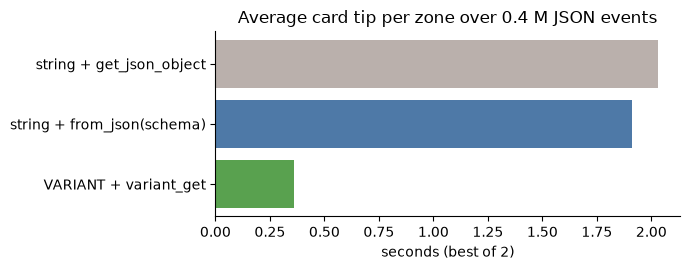

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(var_df["method"], var_df["query s (best of 2)"], color=["#BAB0AC", "#4E79A7", "#59A14F"])
ax.set(title=f"Average card tip per zone over {v_events.count() / 1e6:.1f} M JSON events", xlabel="seconds (best of 2)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

*Insight: All three methods give the same top 5, with JFK (zone 132) first. `variant_get` on the VARIANT column took 0.36 s, about 5x faster than the two methods on the JSON string (2.03 s and 1.91 s). The string methods parse the text of every event; VARIANT reads binary values. The VARIANT files are also half the size (5 MB against 10 MB). A declared schema in `from_json` helps little, because Spark must still parse the text.*

## 5. Python Data Sources and Python UDTFs

The **Python data source API** lets you write a reader in Python and use it like a built-in format. The example
reads the zone lookup CSV with the `csv` module (a real source would call a REST API or read a custom file format).
Spark calls `partitions()` on the driver and `read()` in Python workers, one call per partition.

In [10]:
from pyspark.sql.datasource import DataSource, DataSourceReader, InputPartition

class ZoneReader(DataSourceReader):
    def __init__(self, path: str):
        self.path = path

    def partitions(self):
        return [InputPartition(b) for b in ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island", "EWR", "Unknown", "N/A"]]

    def read(self, partition):
        import csv
        with open(self.path, newline="") as f:
            for r in csv.DictReader(f):
                if r["Borough"] == partition.value:          # each partition reads one borough
                    yield int(r["LocationID"]), r["Borough"], r["Zone"], r["service_zone"]

class ZoneDataSource(DataSource):
    @classmethod
    def name(cls):
        return "taxi_zones"

    def schema(self):
        return "LocationID int, Borough string, Zone string, service_zone string"

    def reader(self, schema):
        return ZoneReader(self.options["path"])

spark.dataSource.register(ZoneDataSource)
pyzones = spark.read.format("taxi_zones").load(ZONES)
print("partitions:", pyzones.rdd.getNumPartitions(), "| rows:", pyzones.count(),
      "| same rows as the CSV reader:", sorted(pyzones.collect()) == sorted(spark.table("zones").collect()))
print(pyzones.groupBy("Borough").count().orderBy(F.desc("count")).toPandas().to_string(index=False))

partitions: 8 | rows: 265 | same rows as the CSV reader: True


      Borough  count
    Manhattan     69
       Queens     69
     Brooklyn     61
        Bronx     43
Staten Island     20
          EWR      1
      Unknown      1
          N/A      1


A **UDTF** (user-defined table function) returns a table: `eval()` can `yield` any number of rows per input row.
The example splits a trip into the clock hours it covers, so that minutes of driving can be counted per hour
(a trip from 08:50 to 09:20 gives 10 minutes in hour 08 and 20 minutes in hour 09). It is used with `LATERAL`
in SQL.

In [11]:
from datetime import timedelta
from pyspark.sql.functions import udtf

@udtf(returnType="hour_start timestamp_ntz, minutes double")
class HourSegments:
    def eval(self, start, end):
        while start < end:
            next_hour = start.replace(minute=0, second=0, microsecond=0) + timedelta(hours=1)
            stop = min(end, next_hour)
            yield next_hour - timedelta(hours=1), (stop - start).total_seconds() / 60
            start = stop

spark.udtf.register("hour_segments", HourSegments)
spark.sql("""SELECT * FROM trips WHERE tpep_pickup_datetime >= '2024-01-15' AND tpep_pickup_datetime < '2024-01-16'
             AND tpep_dropoff_datetime > tpep_pickup_datetime
             AND tpep_dropoff_datetime < tpep_pickup_datetime + INTERVAL 3 HOURS""").createOrReplaceTempView("day")
seg = spark.sql("""SELECT t.tpep_pickup_datetime AS pickup, t.tpep_dropoff_datetime AS dropoff, s.hour_start, ROUND(s.minutes, 2) AS minutes
                   FROM day t, LATERAL hour_segments(t.tpep_pickup_datetime, t.tpep_dropoff_datetime) s""")
seg.cache()
print("UDTF output schema:", seg.select("hour_start", "minutes").schema.simpleString())
spark.sql("""SELECT * FROM day WHERE HOUR(tpep_pickup_datetime) <> HOUR(tpep_dropoff_datetime)
             ORDER BY tpep_pickup_datetime, tpep_dropoff_datetime LIMIT 1""").createOrReplaceTempView("one_trip")
print(spark.sql("""SELECT t.tpep_pickup_datetime AS pickup, t.tpep_dropoff_datetime AS dropoff, s.hour_start, ROUND(s.minutes, 2) AS minutes
                   FROM one_trip t, LATERAL hour_segments(t.tpep_pickup_datetime, t.tpep_dropoff_datetime) s""").toPandas().to_string(index=False))
check = spark.sql("""SELECT COUNT(*) AS trips, SUM(timestampdiff(MICROSECOND, tpep_pickup_datetime, tpep_dropoff_datetime)) / 6e7 AS minutes FROM day""").collect()[0]
print(f"trips: {check.trips:,} -> segments: {seg.count():,} | minutes in trips: {check.minutes:,.0f}, "
      f"in segments: {seg.agg(F.sum('minutes')).collect()[0][0]:,.0f}")
busy = seg.groupBy(F.hour("hour_start").alias("hour")).agg(F.round(F.sum("minutes") / 60).alias("taxi_hours")).orderBy("hour").toPandas()
print("taxi hours driven per clock hour, 2024-01-15 (first 6):", busy.head(6).to_dict("list"))

UDTF output schema: struct<hour_start:timestamp_ntz,minutes:double>


             pickup             dropoff          hour_start  minutes
2024-01-15 00:01:27 2024-01-15 01:01:23 2024-01-15 00:00:00    58.55
2024-01-15 00:01:27 2024-01-15 01:01:23 2024-01-15 01:00:00     1.38


trips: 76,959 -> segments: 95,220 | minutes in trips: 1,091,018, in segments: 1,091,018


taxi hours driven per clock hour, 2024-01-15 (first 6): {'hour': [0, 1, 2, 3, 4, 5], 'taxi_hours': [612.0, 235.0, 146.0, 93.0, 88.0, 107.0]}


## 6. SQL Pipe Syntax

A long SQL query is read inside-out: `FROM` is in the middle, and each subquery adds one more level. **Pipe
syntax** writes the same query as a chain of steps, top to bottom, like a DataFrame program. Each `|>` takes the
result of the previous step. The two queries below compute the top 5 pickup boroughs-and-zones by revenue in the
night hours.

In [12]:
standard = """
SELECT Borough, Zone, COUNT(*) AS trips, ROUND(SUM(total_amount), 2) AS revenue
FROM (SELECT * FROM trips WHERE HOUR(tpep_pickup_datetime) < 5) t
JOIN zones z ON t.PULocationID = z.LocationID
GROUP BY Borough, Zone
ORDER BY revenue DESC
LIMIT 5"""
piped = """
FROM trips
|> WHERE HOUR(tpep_pickup_datetime) < 5
|> JOIN zones ON PULocationID = LocationID
|> AGGREGATE COUNT(*) AS trips, ROUND(SUM(total_amount), 2) AS revenue GROUP BY Borough, Zone
|> ORDER BY revenue DESC
|> LIMIT 5"""
a, b = spark.sql(standard).toPandas(), spark.sql(piped).toPandas()
print(b.to_string(index=False))
print("same result:", a.equals(b))

  Borough                    Zone  trips   revenue
   Queens             JFK Airport  10427 732212.37
Manhattan            East Village  18992 414379.79
Manhattan            West Village  14408 327291.62
Manhattan         Lower East Side  12169 283253.74
Manhattan Greenwich Village South  11918 262489.82
same result: True


*Insight: Both queries return the same five zones, with JFK Airport first (732,212 USD of night trips). Pipe syntax
changes only how the query is written: each step reads top to bottom, and Spark builds the same result.*

## Real-World Use Case or Analogy

Spark Connect is like **ordering in a restaurant**. In classic Spark you walk into the kitchen and cook with the
chef's tools; if you drop a pan, the kitchen stops. With Spark Connect you give the waiter an order (the plan), and
the kitchen sends back the dish (the result). Many guests can order at the same time, and the kitchen can get new
equipment without the guests noticing.

Companies use these features together. Notebook and BI tools connect to a shared Spark Connect server instead of
starting their own driver. ANSI mode makes nightly pipelines stop at the first corrupt value instead of writing
NULLs into a report. Product teams land clickstream and IoT events as VARIANT, so a new field in the app does not
break the table, and analysts still query the fields with SQL.

In [13]:
spark.stop()